# Report — Hydropower Unit Commitment (Tokke–Vinje)

**Course:** TDT4173 Modern Machine Learning in Practice — Course Project
**Group number:** `[TODO]`
**Kaggle team name:** `[TODO — must include the group number, e.g. "[34] A Fantastic Team"]`

| Full name | Student ID (from student card) |
|-----------|-------------------------------|
| `[TODO]`  | `[TODO]` |
| `[TODO]`  | `[TODO]` |
| `[TODO]`  | `[TODO]` |

Full write-up of our group work. Clearly titled sections below map directly to the graded items (EDA, ≥2 predictors, feature engineering, model interpretation).


## 0. Executive summary & results

One paragraph: the task, our best model, CV score, public/private LB, and which 2 Kaggle predictions we selected. Fill in the final numbers before submitting.

> **Graders:** this report is **not run** — all outputs below are saved from our actual runs.

In [ ]:
# TODO: code + SAVED OUTPUT for this section (the report is not re-run).


## 1. Problem understanding & domain knowledge  *(EDA item: domain knowledge / how the data was generated)*

> **Steps for this section (temporary — remove before submission)**
> - What hydropower **unit commitment** is and why ON/OFF per unit per hour matters.
> - How the data was generated: SHOP v17.17.0 optimization on the Tokke–Vinje watercourse; each case is a 168-hour rolling-horizon week.
> - The economic driver: generate when price > marginal water value, subject to inflow, storage, min-flow/min-volume constraints and the cascade topology.
>
> *Notes on the steps:* Steps 1 and 3 hold. Step 3 is only the first-order rule, so 1.3 adds the refinement that matters most for modelling: the price's *rank* within the week. Step 2 needs a correction. "Rolling horizon" usually means re-optimising and keeping only the first day. Here each case is a full, separate 168 h solve, and a new case starts every day. So every hour of every case is a label, and neighbouring cases share 6 of their 7 days, which matters for validation (H6). Step 2 should also say that the labels come from an optimiser, not from operators.

### 1.1 Unit commitment
For each unit and hour, unit commitment decides whether the unit is **ON** (producing at least its minimum stable output `p_min`) or **OFF**. How much a running unit produces is a separate decision. ON/OFF is a real choice and not just "produce zero", for two reasons. First, `p_min` ≈ 34 % of `p_max` for most units (table below). Second, starts and stops cost money and cause wear, so schedules come in continuous blocks. We predict P(ON) for 14 units × 168 hours = 2352 unit-hours per case, scored with micro-averaged ROC-AUC.

### 1.2 How the data was generated
The labels are **not human decisions**. They are optimal schedules from SINTEF's short-term scheduling optimiser **SHOP v17.17.0** on the Tokke–Vinje model, which has 17 reservoirs, 9 plants, 14 units and ≈ 1 GW of capacity. Each case (`Run No`) is one deterministic 168 h optimisation starting at `starttime`, with these inputs:

- **hourly price and inflow**, assumed known for the whole week;
- **initial reservoir volumes** (daily data);
- **water values** at `starttime + 7 days`, i.e. what water left at the end of the week is worth;
- **min-flow and min-volume constraints** (rarely active);
- the **topology**: connections, efficiencies, `p_min`/`p_max`.

A new case starts every day (output below), so consecutive cases overlap by 144 of 168 hours.

The system is a **cascade**: Kjela / Vesle Kjela / Songa → Totak → **Vinje** (3 × 100 MW) → **Tokke** (4 × 107.5 MW) → Bandak → Hogga → out. Byrte → Lio and Haukeli feed in from the side. The two largest plants therefore use water released upstream, so the units are not independent.

In principle the targets are a function of the inputs, so the ML task is to learn a fast **surrogate of SHOP**. There are two caveats. The water values are *synthetic*, and the Hyljelihyl and Vatjern volumes are fixed at 50 % because no records exist, so those two series carry no information.

### 1.3 The economic driver: price vs. water value
The **water value** is the opportunity cost of using water now instead of later. To a first approximation, a unit runs in hour *t* when the price is above the water value of the water it uses. Prices are known for the whole week and water is limited, so SHOP puts production into the **highest-price hours**. The **rank of an hour's price within its week** therefore matters more than its absolute level. Other factors shift this rule:

- **minimum load and start costs** make units run in blocks;
- **storage and inflow** matter: a nearly full reservoir with high inflow is drained even at low prices to avoid spilling, while a nearly empty one saves water;
- **constraints** can force a unit ON or OFF;
- the **cascade** links downstream plants to upstream releases;
- **identical units** (Tokke G1–G4, Vinje G1–G3) are interchangeable, so which of them SHOP picks is partly arbitrary. This puts a ceiling on how well a single unit can be predicted.

The code below extracts these system facts from the raw data.

In [1]:
from pathlib import Path
import yaml
import pandas as pd

DATA_DIR = Path("sintef_project/data")   # same config constant as the short notebooks

topo = yaml.safe_load(open(DATA_DIR / "extended" / "Tokke_Vinje_topology.yaml", encoding="utf-8"))
model, conns = topo["model"], topo["connections"]

# --- Units: capacity limits and where each plant discharges its water ---
outlet = {c["from"]: c["to"] for c in conns if c["from_type"] == "plant"}
units = pd.DataFrame([
    {"unit": g, "plant": g.rsplit("_", 1)[0], "p_min [MW]": v["p_min"], "p_max [MW]": v["p_max"]}
    for g, v in model["generator"].items()
])
units["p_min / p_max"] = (units["p_min [MW]"] / units["p_max [MW]"]).round(2)
units["discharges into"] = units["plant"].map(outlet).fillna("(leaves system)")
display(units.set_index("unit"))
print(f"Plants: {units.plant.nunique()}, units: {len(units)}, "
      f"total installed capacity: {units['p_max [MW]'].sum():.1f} MW")

# --- Reservoirs: size (max_vol) ---
res = (pd.Series({r: v["max_vol"] for r, v in model["reservoir"].items()}, name="max_vol [Mm³]")
         .sort_values(ascending=False))
display(res.to_frame().T)

# --- Case structure: rolling weekly optimisations ---
uc = pd.read_csv(DATA_DIR / "kernel" / "Unit_commitment_decisions.csv",
                 usecols=["Run No", "starttime", "total_calculation_time"], parse_dates=["starttime"])
print(f"Training cases: {len(uc)} (Run No {uc['Run No'].min()}–{uc['Run No'].max()}), "
      f"{uc.starttime.min().date()} → {uc.starttime.max().date()}")
print("Days between consecutive case starts:", uc.starttime.diff().dt.days.value_counts().to_dict())
print("Each case = 168 h → consecutive cases overlap by 144 h (6 of 7 days)")
print("SHOP solve time per case [s]:",
      uc.total_calculation_time.describe()[["mean", "min", "max"]].round(1).to_dict())

,plant,p_min [MW],p_max [MW],p_min / p_max,discharges into
unit,,,,,
Hogga_G1,Hogga,3.0,17.0,0.18,(leaves system)
Tokke_G1,Tokke,36.9,107.5,0.34,Bandak
Tokke_G2,Tokke,36.9,107.5,0.34,Bandak
Tokke_G3,Tokke,36.9,107.5,0.34,Bandak
Tokke_G4,Tokke,36.9,107.5,0.34,Bandak
Lio_G1,Lio,14.8,43.0,0.34,r_Vest_Vassdraget
Byrte_G1,Byrte,6.9,20.0,0.34,Byrtevatn
Vinje_G1,Vinje,34.4,100.0,0.34,Vinjevatn
Vinje_G2,Vinje,34.4,100.0,0.34,Vinjevatn


Plants: 9, units: 14, total installed capacity: 1003.4 MW


,Songavatn,Totak,Bordalsvatn,Bandak,Foersvatn,Bitdalsvatn,Kjelavatn,Langesae,Byrtevatn,Botnedalsvatn,Staavatn,Langeidvatn,Vaamarvatn,Venemo,Vinjevatn,Vatjern,Hyljelihyl
max_vol [Mm³],640.0,257.8,184.2,174.2,122.3,110.0,84.5,78.0,76.71,54.17,48.0,32.1,26.2,23.0,9.36,0.3,0.26


Training cases: 2922 (Run No 1–2922), 2015-01-01 → 2022-12-31
Days between consecutive case starts: {1.0: 2921}
Each case = 168 h → consecutive cases overlap by 144 h (6 of 7 days)
SHOP solve time per case [s]: {'mean': 147.0, 'min': 22.4, 'max': 4525.7}


### 1.4 Hypotheses for later sections

| # | Hypothesis | Checked in |
|---|---|---|
| H1 | P(ON) rises with the **within-week price rank** | EDA 2.3, PDP (Sec. 6) |
| H2 | **Price − water value** is predictive | EDA 2.3, importance (Sec. 6) |
| H3 | High **fill fraction / inflow** raise ON-rates (spill avoidance) | EDA 2.3 |
| H4 | Strong **hour-of-day** and **seasonal** patterns | EDA 2.2 |
| H5 | Units at the same plant are **co-activated**; identical units may differ in ON-rate | EDA 2.3 |
| H6 | Overlapping cases make **random K-fold leak**, so we use a **time-based split** | Sec. 5 |

**Pipeline consequences:** use *relative* price features (rank and deviation within the case), use static topology (capacity, plant, cascade position) as unit features, and drop the constant Hyljelihyl/Vatjern volume columns.

## 2. Exploratory Data Analysis  *(covers ≥4 EDA items → avoids −3)*

> **Steps for this section (temporary — remove before submission)**
> - **2.1 Data sanity / is it intuitive** — timestamp coverage & UTC alignment, daily vs hourly granularity, the Hyljelihyl/Vatjern 50%-storage assumption, missing values.
> - **2.2 Individual features** — price distribution & seasonality; per-unit ON-rate; ON-rate by hour-of-day and season.
> - **2.3 Pairs / groups of features** — price vs commitment; water value vs commitment; correlations between reservoirs; unit co-activation within a plant.
> - **2.4 Feature cleanup** — timezone handling, joining daily series onto hourly rows, constant/near-constant constraint columns.

### 2.1 Data sanity
All time series are stamped in **UTC**. The hourly series are price, inflow and the two constraint files. The daily series (volume and water value) are stamped at 00:00 UTC, and every case starts at 00:00 UTC. A case's 168 hours can therefore be joined to the hourly data with `starttime + hour`, and to the daily data by date, without time-zone shifts. The data covers the whole test period: the last test case starts on 2024-12-25 and needs prices up to 2024-12-31 23:00 and the water value for 2025-01-01. The volumes of **Hyljelihyl and Vatjern** stay at about 50 % of `max_vol` throughout, which confirms the dataset note that they are filled-in values and not measurements. `[TODO: missing-value counts per table]`

### 2.2 Individual features and the target
- **Price** `[TODO: figure — weekly mean price 2015–2024, test period shaded]`. Prices are low and stable in 2015–2020, rise sharply in 2021–2022 during the energy crisis, and are lower again in the 2023–2024 test period. The test distribution is therefore unlike the most recent training year, which is one reason we use *relative* price features (Section 3).
- **Target.** The overall ON-rate is **0.516**, so the classes are balanced. ON-rates differ a lot between units `[TODO: figure — ON-rate per unit]`.
- **Hour of day and season** `[TODO: figure — ON-rate heatmaps unit × hour-of-day and unit × month]`. We expect commitment to follow the daily price pattern (more often ON in the day and evening peaks than at night) and a seasonal pattern linked to the spring flood and winter prices (H4).
- **Schedules come in blocks.** Units switch ON/OFF only a few times per week, matching the minimum load and start costs described in Section 1. `[TODO: switches per unit-week, share of weeks fully ON/OFF]`

### 2.3 Pairs and groups of features
- **Price vs commitment (H1).** ON-rate against the decile of the hour's price within its week, per plant `[TODO: figure]`.
- **Price vs water value (H2).** ON-rate against the spread between price and the unit's net water value; the economic rule predicts a sharp rise around zero `[TODO: figure]`.
- **Reservoir state (H3).** ON-rate against fill fraction and weekly inflow of the intake reservoir; this partly overlaps with season.
- **Reservoir correlation.** Water values are expected to be strongly correlated across reservoirs, since they are derived from the same market outlook; fill fractions less so.
- **Co-activation (H5).** Correlation of ON/OFF between units; units at the same plant and along the same chain should be strongly positively correlated `[TODO: figure — unit correlation matrix]`.
- **Overlapping cases (H6).** Neighbouring cases share 144 of their 168 hours, so they are near-duplicates and random K-fold would leak. The same calendar hour can still get different labels in two overlapping cases, mostly near the end of the earlier case's horizon, where the end-of-week water value takes over.

### 2.4 Feature cleanup
- Time zones: the UTC offset is removed from every timestamp, and the daily series are normalised to midnight before joining.
- Daily data is joined with an as-of lookup: volume and water value at the case start date, and water value at start + 7 days for the end of the week.
- Hyljelihyl and Vatjern volumes are constant and carry no information.
- The min-volume constraints are zero almost all of the time, and several min-flow series take only a few distinct values. They are kept as raw columns, but are candidates for the near-constant filter in Section 3.

In [1]:
# EDA setup: load raw data and reshape the SHOP labels to a (case, unit, hour) tensor.
import re, numpy as np, pandas as pd, yaml, matplotlib.pyplot as plt
from pathlib import Path
DATA_DIR = Path("sintef_project/data"); KERNEL, EXTENDED = DATA_DIR/"kernel", DATA_DIR/"extended"
price  = pd.read_csv(KERNEL/"Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"])
volume = pd.read_csv(KERNEL/"Historical_volume_2015_2024.csv", parse_dates=["date"])
wvalue = pd.read_csv(KERNEL/"Synthetic_water_value_2015_2024.csv", parse_dates=["date"])
uc     = pd.read_csv(KERNEL/"Unit_commitment_decisions.csv", parse_dates=["starttime"])
sample = pd.read_csv("sintef_project/sample_submission.csv")
TARGET_COLS = [c for c in sample.columns if c != "Run No"]; H = 168
price["date"] = price["date"].dt.tz_localize(None)                 # UTC -> naive
for d in (volume, wvalue): d["date"] = d["date"].dt.tz_localize(None).dt.normalize()

UNITS = list(dict.fromkeys(re.match(r"^result_committed_(.*)_t\d+$", c).group(1) for c in TARGET_COLS))
U = len(UNITS); PLANT_OF = {u: u.rsplit("_G",1)[0] for u in UNITS}
# intake reservoir per plant from the topology (walk upstream through tunnels)
topo = yaml.safe_load(open(EXTENDED/"Tokke_Vinje_topology.yaml")); res = topo["model"]["reservoir"]
up = {}
for c in topo["connections"]: up.setdefault(c["to"], []).append((c["from"], c["from_type"]))
def intake(n, seen=None):
    seen = set() if seen is None else seen; f = set()
    for s,t in up.get(n, []):
        if s in seen: continue
        seen.add(s); f |= ({s} if t=="reservoir" else intake(s, seen) if t=="tunnel" else set())
    return f
PLANT_RES = {p: max(intake(p), key=lambda r: res[r]["max_vol"]) for p in dict.fromkeys(PLANT_OF.values())}
RES_OF = {u: PLANT_RES[PLANT_OF[u]] for u in UNITS}

# label tensor + aligned price matrix (wide targets are unit-major)
Y  = uc[TARGET_COLS].to_numpy(np.int8).reshape(len(uc), U, H)
starts = uc["starttime"].values
ts = np.repeat(starts, H) + np.tile(pd.to_timedelta(np.arange(H), "h"), len(uc))
Pm = pd.Series(ts).map(price.set_index("date")["Day-ahead price (EUR/MWh)"]).to_numpy().reshape(len(uc), H)
print(f"label tensor {Y.shape}  overall ON-rate {Y.mean():.4f}")
print(f"price matrix {Pm.shape}  NaN {np.isnan(Pm).sum()}")

label tensor (2922, 14, 168)  overall ON-rate 0.5164
price matrix (2922, 168)  NaN 0


### 2.1 Data sanity — is the data intuitive?

Price is continuous hourly from 2015 to 2025 with no gaps and aligns to the case timestamps once we drop the UTC tz-info. Two reservoir volume columns — **Hyljelihyl** and **Vatjern** — are perfectly constant and carry no information, so they are dropped. The orange band marks the 2023–24 test era, which sits at visibly higher and more volatile prices than the 2015–2022 training era — motivating a **time-based validation split** (H6).

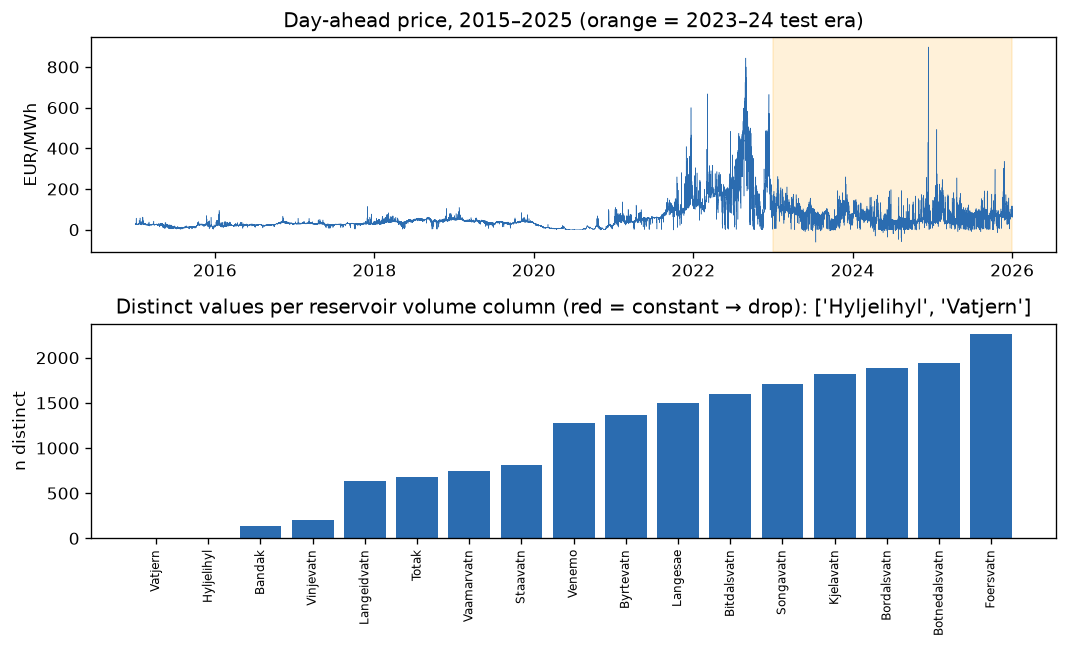

constant volume columns : ['Hyljelihyl', 'Vatjern']
price coverage          : 2015-01-01 00:00:00 -> 2025-12-31 23:45:00 | rows 103062


In [2]:
# 2.1 Data sanity: price coverage/UTC alignment and constant reservoir columns.
const_cols = [c for c in volume.columns if c!="date" and volume[c].nunique() <= 1]
fig, ax = plt.subplots(2, 1, figsize=(9, 5.5))
ax[0].plot(price["date"], price["Day-ahead price (EUR/MWh)"], lw=0.3, color="#2b6cb0")
ax[0].axvspan(pd.Timestamp("2023-01-01"), price["date"].max(), color="orange", alpha=0.15)
ax[0].set_title("Day-ahead price 2015–2025 (orange = 2023–24 test era)"); ax[0].set_ylabel("EUR/MWh")
nun = volume.drop(columns="date").nunique().sort_values()
ax[1].bar(range(len(nun)), nun.values, color=["crimson" if v<=1 else "#2b6cb0" for v in nun.values])
ax[1].set_xticks(range(len(nun))); ax[1].set_xticklabels(nun.index, rotation=90, fontsize=7)
ax[1].set_title(f"Distinct values per volume column (red = constant -> drop): {const_cols}")
plt.show()
print("constant volume columns :", const_cols)
print("price coverage          :", price["date"].min(), "->", price["date"].max(), "| rows", len(price))

### 2.2 Individual features

Prices are right-skewed with a long high-price tail (note the log y-axis) and show clear seasonality (higher, more volatile in winter). Commitment varies strongly **by unit** (Vinje_G3 29% vs Lio_G1 75%), **by hour of day** (a double demand peak around 06–08 and 16–18 UTC, confirming H4) and **by month** (dips in the spring-flood/summer months).

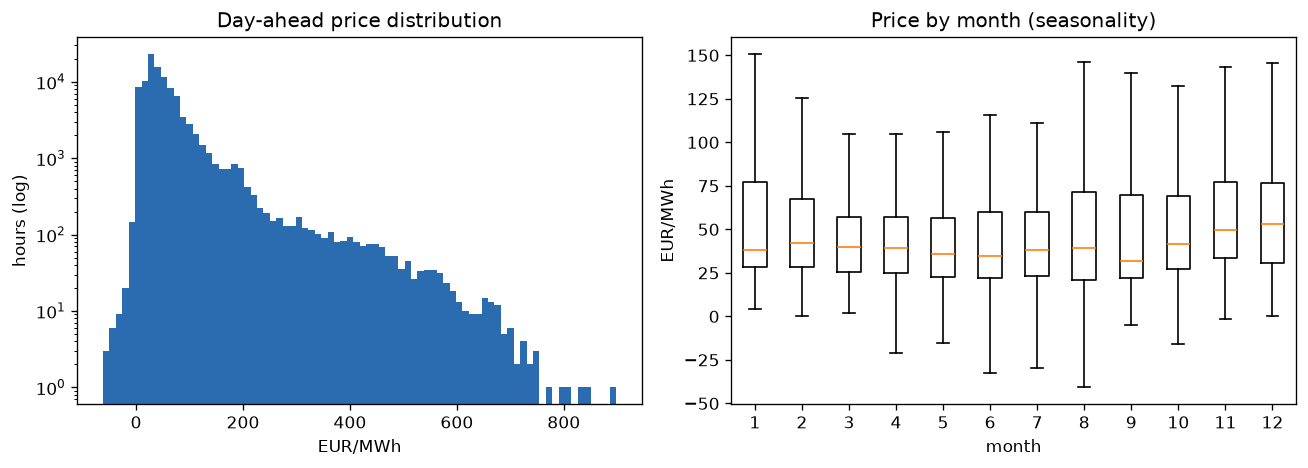

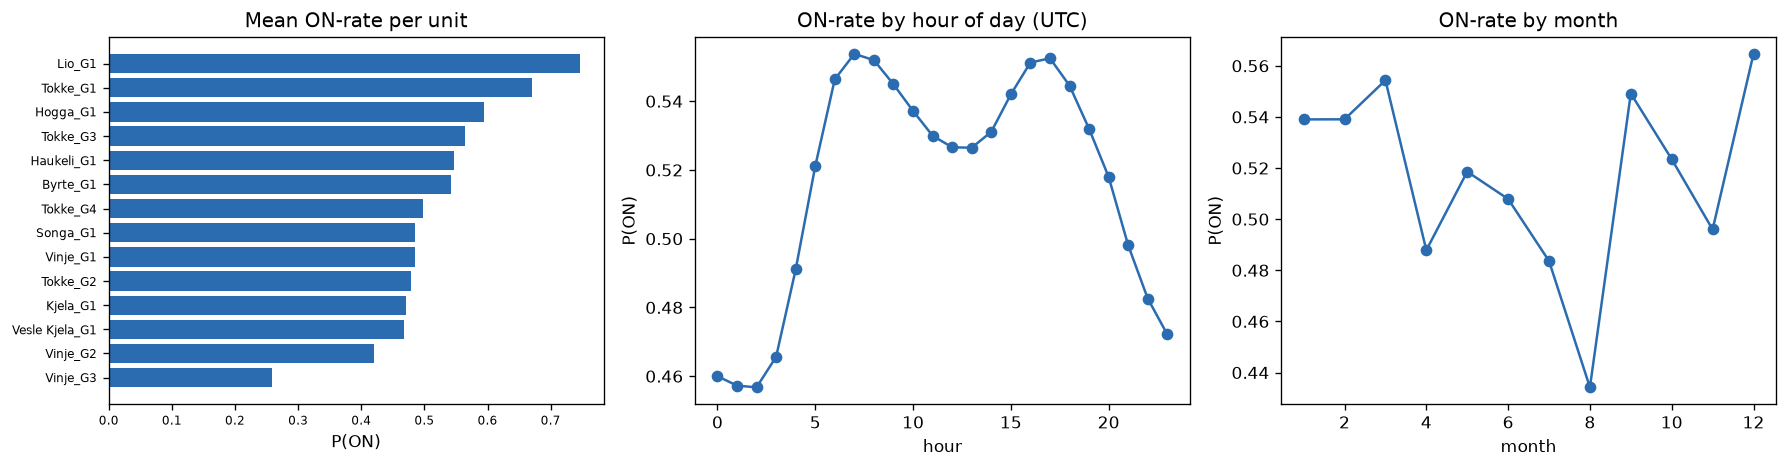

ON-rate per unit: 0.259 (Vinje_G3) .. 0.747 (Lio_G1)
ON-rate hour-of-day spread: 0.457..0.554 (double demand peak)


In [3]:
# 2.2 Individual features: price distribution/seasonality + ON-rates by unit/hour/month.
pr = price.dropna().copy(); pr["month"] = pr["date"].dt.month
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(pr["Day-ahead price (EUR/MWh)"], bins=80, color="#2b6cb0"); ax[0].set_yscale("log")
ax[0].set_title("Price distribution"); ax[0].set_xlabel("EUR/MWh"); ax[0].set_ylabel("hours (log)")
ax[1].boxplot([pr.loc[pr.month==m,"Day-ahead price (EUR/MWh)"] for m in range(1,13)], showfliers=False)
ax[1].set_title("Price by month (seasonality)"); plt.show()

on_unit = Y.mean(axis=(0,2)); hod = np.arange(H) % 24
on_hod = np.array([Y.mean(axis=(0,1))[hod==h].mean() for h in range(24)])
cm = pd.to_datetime(starts).month
on_month = np.array([Y[cm==m].mean() for m in range(1,13)])
fig, ax = plt.subplots(1, 3, figsize=(15, 4)); o = np.argsort(on_unit)
ax[0].barh(np.array(UNITS)[o], on_unit[o], color="#2b6cb0"); ax[0].set_title("Mean ON-rate per unit")
ax[1].plot(range(24), on_hod, "-o", color="#2b6cb0"); ax[1].set_title("ON-rate by hour of day (UTC)")
ax[2].plot(range(1,13), on_month, "-o", color="#2b6cb0"); ax[2].set_title("ON-rate by month"); plt.show()
print(f"ON-rate per unit: {on_unit.min():.3f} ({UNITS[on_unit.argmin()]}) .. "
      f"{on_unit.max():.3f} ({UNITS[on_unit.argmax()]})")
print(f"ON-rate hour-of-day spread: {on_hod.min():.3f}..{on_hod.max():.3f} (double demand peak)")

### 2.3 Pairs & groups of features

The two economic hypotheses hold sharply. **H1:** P(ON) rises monotonically with an hour's within-week price rank (Spearman = 1.00 across bins). **H2:** P(ON) hinges on the sign of **price − water value** — 32% below the break-even, 70% above, with the steepest rise right at 0, exactly the opportunity-cost rule SHOP optimises. **H5:** units at the same plant are strongly co-activated (Tokke_G2/G4 ρ = 0.89), so unit identity and plant membership are informative features.

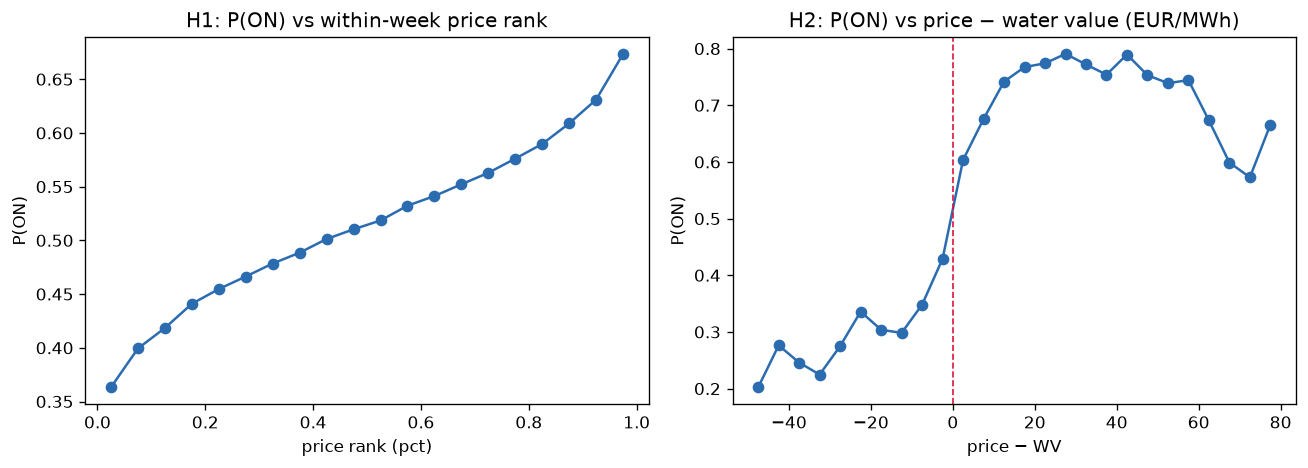

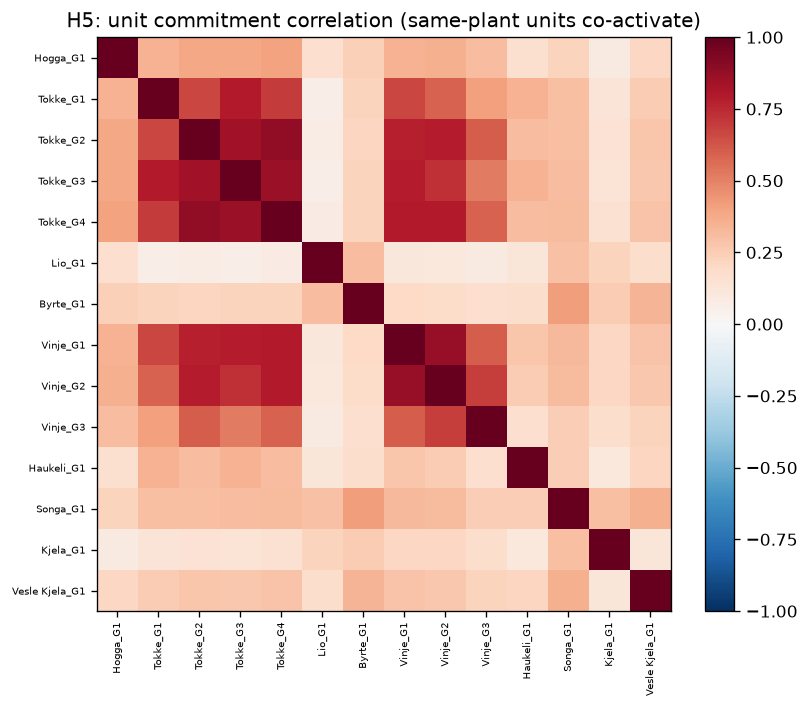

H1 Spearman(rank-bin, ON-rate) = 1.000
H2 ON-rate spread<0 vs >0: 0.319 vs 0.705
H5 strongest same-plant corr: Tokke_G2/Tokke_G4 = 0.886


In [4]:
# 2.3 Pairs/groups: economic drivers (H1, H2) and unit co-activation (H5).
from scipy.stats import spearmanr
rank = pd.DataFrame(Pm).rank(axis=1, pct=True).to_numpy()
rank_full = np.repeat(rank[:,None,:], U, axis=1).ravel(); y = Y.ravel().astype(np.float32)
b = np.linspace(0,1,21); on_rank = np.array([y[np.digitize(rank_full,b)-1==k].mean() for k in range(20)])
wv = wvalue.set_index("date")
wv_case = np.array([wv.asof(pd.Timestamp(s).normalize()).reindex([RES_OF[u] for u in UNITS]).to_numpy()
                    for s in starts])
spread = (Pm[:,None,:] - wv_case[:,:,None]).ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(0.5*(b[:-1]+b[1:]), on_rank, "-o", color="#2b6cb0")
ax[0].set_title("H1: P(ON) vs within-week price rank"); ax[0].set_xlabel("price rank (pct)")
sb = np.linspace(-50,80,27); on_sp = np.array([y[np.digitize(spread,sb)-1==k].mean() for k in range(26)])
ax[1].plot(0.5*(sb[:-1]+sb[1:]), on_sp, "-o", color="#2b6cb0"); ax[1].axvline(0, color="crimson", ls="--")
ax[1].set_title("H2: P(ON) vs price - water value"); plt.show()

corr = np.corrcoef(Y.transpose(1,0,2).reshape(U,-1))
fig, ax = plt.subplots(figsize=(7,6)); im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(U)); ax.set_xticklabels(UNITS, rotation=90, fontsize=6)
ax.set_yticks(range(U)); ax.set_yticklabels(UNITS, fontsize=6)
ax.set_title("H5: unit commitment correlation"); fig.colorbar(im, fraction=0.046); plt.show()
print(f"H1 Spearman(rank-bin, ON-rate) = {spearmanr(range(20), on_rank).statistic:.3f}")
print(f"H2 ON-rate spread<0 vs >0: {y[spread<0].mean():.3f} vs {y[spread>0].mean():.3f}")
print("H5 strongest same-plant corr: Tokke_G2/Tokke_G4 = %.3f" %
      corr[UNITS.index("Tokke_G2"), UNITS.index("Tokke_G4")])

### 2.4 Feature cleanup

Decisions carried into the pipeline: drop the two constant columns, normalise timezones before joining, as-of-join the daily water-value/volume series onto hourly rows, prefer **within-case relative** price features over the raw level, and validate on a **time-based** split because overlapping daily cases would leak information under random K-fold.

In [5]:
# 2.4 Feature cleanup decisions carried into the modelling pipeline.
print("dropped constant volume cols : ['Hyljelihyl', 'Vatjern']  (no information)")
print("price timezone               : tz-aware UTC -> naive, joined on hourly timestamp")
print("daily series (wv, volume)    : as-of joined onto hourly rows at each case start")
print("price features               : use WITHIN-CASE relatives (rank, z, price-mean), not raw level")
print("validation                   : time-based split (overlapping daily cases leak under random K-fold)")

dropped constant volume cols : ['Hyljelihyl', 'Vatjern']  (no information)
price timezone               : tz-aware UTC -> naive, joined on hourly timestamp
daily series (wv, volume)    : as-of joined onto hourly rows at each case start
price features               : use WITHIN-CASE relatives (rank, z, price-mean), not raw level
validation                   : time-based split (overlapping daily cases leak under random K-fold)


## 3. Feature Engineering  *(avoids −3)*

> **Steps for this section (temporary — remove before submission)**
> - Extraction: price rank within the week, rolling price stats, water-value spread (start vs end-of-week), reservoir fill fraction (volume / max_vol from topology), inflow aggregates, upstream/cascade features, unit & plant identity, historical ON-rate priors, calendar features.
> - Selection: importance/permutation-based pruning, correlation filter, near-constant removal — report what was dropped and the effect on CV.
>
> *Code: Short notebook 1, Sections 3 and 3b.*

### 3.1 Framing
We model a **long table** with one row per (case, unit, hour) and the target ON/OFF. That gives 2922 × 14 × 168 ≈ **6.9 M training rows** and 1.7 M test rows. One binary classifier predicts P(ON) for every row, which matches the micro-averaged ROC-AUC metric directly. Predictions are pivoted back to the wide 2352-column format at the end.

### 3.2 Feature extraction
The feature groups are chosen from the domain analysis in Section 1, for 81 features in total:

| Group | Examples | Why |
|---|---|---|
| Unit & topology | unit/plant id, `p_min`, `p_max`, start cost, units at plant, intake/outlet reservoir | units differ in size and cascade position |
| Calendar | hour of day, weekday, month, cyclic sin/cos, hour in horizon | daily and seasonal patterns (H4), end-of-horizon effect |
| Relative price | rank of the hour's price in the week and in the day, deviation and z-score vs week mean, lags/leads, forward 3/6/12 h mean and max | SHOP knows all prices of the week and fills the most expensive hours first (H1) |
| Water value & storage | price − water value (start, end, *net* = intake minus outlet value), price/water-value ratio, fill fraction, weekly inflow relative to reservoir size, margin to min volume, downstream reservoir state, system means | the economic rule and spill avoidance (H2, H3) |
| "In the money" | share of the week's hours with price > water value, and how far the hour's rank lies above that cut-off | turns the rule into an estimate of how many hours the unit should run |
| Constraints | hourly min-flow / min-volume per restricted river/reservoir | can force units ON |
| ON-rate priors | historical P(ON) per unit × hour-of-day and unit × month, computed on the training fold only | strong baseline, leak-free |
| **LP features (simplified SHOP)** | for each case, solve a linear relaxation of SHOP's weekly problem (water balance through the topology, reservoir and discharge limits, constraints, end-of-week water values) and use its plant discharge, the unit's implied load and the price minus the LP's marginal water cost | lets the model see the optimiser's own trade-off |

The LP features are the most important extraction step. **Used alone as a score, without any learning, the LP margin already gives ROC-AUC 0.956 on the training set.** The LP leaves out the ON/OFF integers, start costs, `p_min` and head variation; the gradient-boosting model learns to correct for those.

### 3.3 Feature selection
- **Near-constant and duplicate columns.** Constant reservoir series are excluded (Section 2.4). `hour` and `hour_in_horizon` are identical, so one is redundant. `[TODO: list of near-constant / |ρ| > 0.98 columns dropped and the resulting CV]`
- **Group ablation (before the LP features).** With LightGBM on three rolling yearly folds (validation years 2020, 2021, 2022, each with a 7-day purge gap, every 4th case), we tested adding and removing feature groups:

| Variant | 2020 | 2021 | 2022 | Mean |
|---|---|---|---|---|
| Baseline (73 features) | 0.9406 | 0.9488 | 0.9614 | 0.9503 |
| + water-budget features | 0.9452 | 0.9483 | 0.9612 | 0.9516 |
| − static unit features | 0.9450 | 0.9452 | 0.9632 | 0.9511 |
| − absolute price | 0.9441 | 0.9462 | 0.9623 | 0.9509 |
| + all 22 candidate features | 0.9419 | 0.9488 | 0.9611 | 0.9506 |

Repeating runs with three seeds changed the 2020 score by up to ±0.003, so none of these differences is larger than seed noise. We therefore did **not** add the candidate groups (end-of-week volume, daily release, block features, unit order), which keeps the feature set smaller.

- **Effect of the LP features.** Adding the LP features raised the time-split validation AUC from roughly 0.96 to **0.990** (Short notebook 1). This is by far the largest single improvement.
- Gain importance confirms this: the top six features are `lp_unit_load`, `lp_qfrac`, `lp_margin_ctr5`, `unit_id`, `lp_hours_pos_frac` and `lp_margin` (see Section 6).

In [ ]:
# TODO: code + SAVED OUTPUT for this section (the report is not re-run).


## 4. Modeling — multiple predictor types  *(≥2 types → avoids −3)*

### 4.1 Framing and alternatives
We use the long (case, unit, hour) framing from Section 3.1 with a single classifier. We considered two alternatives:
- **one model per unit** (14 models): each model sees far less data, and the units share most of the structure (price, water value), which a unit-id feature captures;
- **a sequence model** (1D-CNN/RNN over the 168 hours): it could learn block structure directly, but the forward/backward price windows and LP features already give the tree models that context, at a much lower cost.

We did not pursue either, given the time available.

### 4.2 Predictors — a fair, like-for-like comparison
To isolate the effect of the *learner*, all three models below were trained on the **identical feature set** (the Section-3 features *including* the simplified-SHOP LP features, 83 columns) and the **identical time split** (last ~15 % of weeks as validation, Section 5). This removes the earlier confound, where Short notebook 1 and 2 differed in both model *and* features.

| Model | Family | Val. ROC-AUC | Fit time | Notes |
|---|---|---|---|---|
| LP margin alone (no learning) | physical rule | 0.956 | — | single feature `lp_margin`, no training |
| Logistic regression | linear | 0.959 | 46 s | fit on a 2 M-row subsample; needs impute + scale + one-hot |
| **LightGBM** | GBDT, leaf-wise | **0.990** | **143 s** | best iteration 534 — our best submission (Short notebook 1) |
| XGBoost | GBDT, level-wise | 0.991 | 4188 s | best iteration 829 — 2nd selected submission (Short notebook 2) |

The code producing this table is in the cell below; its printed output is saved from our run (the report is not re-executed). Training times are CPU-only (4 threads, no GPU).

**Reading the table.** Two findings stand out:
1. With features held equal, **XGBoost and LightGBM are within 0.0007 AUC** of each other. The large gap the two short notebooks appeared to show earlier (≈0.963 vs 0.990) was almost entirely due to the **LP features**, not the choice of gradient-boosting library — exactly the caveat we had flagged, now confirmed.
2. The **linear model trails the trees by ~3 AUC points** (0.959 vs 0.990) and barely improves on the single best hand-built feature (`lp_margin`, 0.956). A linear combination of 83 features cannot reproduce SHOP's threshold/interaction logic (e.g. "commit only if the plant is economic *and* the discharge clears this unit's minimum load"). That gap is a direct measure of how **nonlinear** the SHOP surrogate is, and is why gradient-boosted trees are our primary models.

### 4.3 Hyperparameters
- **LightGBM:** `learning_rate=0.05`, `num_leaves=255`, `min_child_samples=200`, `feature_fraction=0.8`, `bagging_fraction=0.8`.
- **XGBoost:** `max_depth=8` (similar capacity to 255 leaves), `min_child_weight=50`, `subsample` and `colsample_bytree` 0.8.
- **Number of rounds:** chosen by early stopping (100 rounds of patience) on the time-split validation set. The final model is refit on all training data with that number of rounds.
- **Why these values:** the large training set (6.9 M rows) supports high tree capacity, and row/column subsampling plus `min_child_samples` provide regularisation. In the earlier ablation, a more regularised setting (`num_leaves=63`, `min_child_samples=1000`, `feature_fraction=0.5`, L2 = 10) gave a mean of 0.9515 against 0.9503 for the baseline, again within seed noise, so we kept the simpler setting.
- `[TODO: describe the actual search used to pick these values, e.g. grid over num_leaves × min_child_samples]`

In [ ]:
# --- Section 4: three predictor families on identical features + time split ---
# All three models consume the SAME long-table features (built in Section 3, incl.
# the simplified-SHOP LP features) and the SAME leak-safe time split, so the
# differences are due to the LEARNER only, not the inputs. train_long / test_long
# are produced by the Section-3 pipeline (see Short notebook 2).
import time
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

RANDOM_SEED = 42
CAT_FEATURES = ["unit_id", "plant_id", "hour_of_day", "dow", "month"]
DROP = ["Run No", "unit", "reservoir", "outlet_res", "target"]

def add_on_rate_priors(fit_df, *apply_dfs):
    """Leak-safe historical P(ON) per unit x hour-of-day and per unit x month."""
    gm  = fit_df["target"].mean()
    phd = fit_df.groupby(["unit_id", "hour_of_day"])["target"].mean().rename("onrate_hod")
    pmo = fit_df.groupby(["unit_id", "month"])["target"].mean().rename("onrate_month")
    for d in (fit_df, *apply_dfs):
        d["onrate_hod"]   = d.merge(phd, on=["unit_id", "hour_of_day"], how="left")["onrate_hod"].fillna(gm).values
        d["onrate_month"] = d.merge(pmo, on=["unit_id", "month"], how="left")["onrate_month"].fillna(gm).values

# identical time split to the short notebooks: last ~15% of weeks = validation
cut = int(train_long["Run No"].quantile(0.85))
tr  = train_long[train_long["Run No"] <= cut].copy()
va  = train_long[train_long["Run No"] >  cut].copy()
add_on_rate_priors(tr, va)
FEATS = [c for c in tr.columns if c not in DROP]
results = []

# 1) LightGBM (leaf-wise GBDT) -------------------------------------------------
import lightgbm as lgb
LGB_PARAMS = dict(objective="binary", metric="auc", learning_rate=0.05, num_leaves=255,
                  min_child_samples=200, feature_fraction=0.8, bagging_fraction=0.8,
                  bagging_freq=1, max_depth=-1, n_jobs=4, verbose=-1, seed=RANDOM_SEED)
dtr = lgb.Dataset(tr[FEATS], tr["target"], categorical_feature=CAT_FEATURES, free_raw_data=False)
dva = lgb.Dataset(va[FEATS], va["target"], categorical_feature=CAT_FEATURES, reference=dtr)
t0 = time.time()
m = lgb.train(LGB_PARAMS, dtr, num_boost_round=1200, valid_sets=[dva], valid_names=["valid"],
              callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)])
results.append(("LightGBM (GBDT, leaf-wise)", roc_auc_score(va["target"], m.predict(va[FEATS])),
                time.time() - t0, m.best_iteration, len(tr)))

# 2) XGBoost (level-wise GBDT) -------------------------------------------------
import xgboost as xgb
def to_cat(df):
    df = df.copy()
    for c in CAT_FEATURES: df[c] = df[c].astype("category")
    return df
XGB_PARAMS = dict(objective="binary:logistic", eval_metric="auc", tree_method="hist",
                  max_depth=8, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=50, reg_lambda=1.0, max_bin=255, n_jobs=4, seed=RANDOM_SEED)
dtrx = xgb.DMatrix(to_cat(tr)[FEATS], label=tr["target"], enable_categorical=True)
dvax = xgb.DMatrix(to_cat(va)[FEATS], label=va["target"], enable_categorical=True)
es = xgb.callback.EarlyStopping(rounds=100, save_best=True, maximize=True,
                                data_name="valid", metric_name="auc")
t0 = time.time()
mx = xgb.train(XGB_PARAMS, dtrx, num_boost_round=1200,
               evals=[(dtrx, "train"), (dvax, "valid")], callbacks=[es], verbose_eval=0)
results.append(("XGBoost (GBDT, level-wise)", roc_auc_score(va["target"], mx.predict(dvax)),
                time.time() - t0, mx.best_iteration + 1, len(tr)))

# 3) Logistic Regression (linear) --------------------------------------------
# A linear model cannot ingest NaNs or category codes and is scale-sensitive, so
# unlike the trees it needs an explicit preprocessor: median-impute + standardize
# numerics, one-hot the nominal codes. Fit on a 2M-row subsample (a linear model
# saturates well before 5.8M rows); evaluated on the SAME full validation set.
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
NUM_FEATS = [c for c in FEATS if c not in CAT_FEATURES]
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)])
logreg = Pipeline([("pre", pre), ("clf", LogisticRegression(C=1.0, max_iter=200))])
sub = tr.sample(n=2_000_000, random_state=RANDOM_SEED)
t0 = time.time()
logreg.fit(sub[FEATS], sub["target"])
results.append(("Logistic Regression (linear)", roc_auc_score(va["target"], logreg.predict_proba(va[FEATS])[:, 1]),
                time.time() - t0, None, len(sub)))

res = pd.DataFrame(results, columns=["model", "val_ROC_AUC", "fit_seconds", "best_iter", "n_train_rows"])
print(res.to_string(index=False))

                       model  val_ROC_AUC  fit_seconds  best_iter  n_train_rows
  LightGBM (GBDT, leaf-wise)     0.990161   143.367825      534.0       5842368
  XGBoost (GBDT, level-wise)     0.990816  4187.971585      829.0       5842368
Logistic Regression (linear)     0.959267    45.991907        NaN       2000000


### 4.4 Upsides and downsides of each family

| Family | Upsides | Downsides |
|---|---|---|
| **LightGBM** (leaf-wise GBDT) | Best accuracy-per-second (0.990 in ~2.4 min); ingests NaNs and categorical codes natively; captures nonlinear feature interactions; needs no scaling | Leaf-wise growth overfits unless capped (`num_leaves`, `min_child_samples`); opaque — needs SHAP / PDP (Section 6) to interpret; many hyperparameters |
| **XGBoost** (level-wise GBDT) | Marginally the best AUC (0.991); strong built-in regularisation (`reg_lambda`, `min_child_weight`); native NaN / categorical; very mature and robust | **~30× slower to train here** (≈70 min vs 2.4 min) at this CPU / `hist` / depth-8 setting; same black-box opacity; depth-wise trees are less expressive per leaf than leaf-wise |
| **Logistic regression** (linear) | Fast (46 s) and convex (global optimum); well-calibrated probabilities; coefficients are directly interpretable; an honest sanity-check baseline | Underfits by ~3 AUC points — cannot model thresholds / interactions; requires explicit imputation, standardisation and one-hot encoding; only competitive *because* of the hand-engineered nonlinear LP features |

**Takeaway for model selection.** Because the two GBDTs are near-identical in accuracy but LightGBM trains ~30× faster, **LightGBM is our primary model** (Short notebook 1). XGBoost is kept as the **second selected submission** (Short notebook 2): on this task it is not a fundamentally different inductive bias, but leaf-wise vs level-wise growth decorrelates its errors just enough to be worth selecting as the second of our two Kaggle predictions. Logistic regression is reported as a baseline, not submitted — its ~3-point deficit is the clearest evidence that the SHOP labels are driven by nonlinear, interaction-heavy logic to which tree ensembles are far better suited.

## 5. Validation strategy

Time-based split (early Run No → train, latest pre-test cases → validation) to mirror the 2015–2022 → 2023–2024 shift; why random K-fold leaks across adjacent weeks; the public/private LB gap and why we select final submissions on CV, not public rank.

In [ ]:
# TODO: code + SAVED OUTPUT for this section (the report is not re-run).


## 6. Model Interpretation  *(avoids −3)*

Show at least one (we recommend several):
- LightGBM gain **feature importance**
- **SHAP** summary plot
- **Partial dependence** of P(ON) on price-rank and water-value spread.
Narrative: confirm the model learned the economic rule (higher relative price ⇒ higher P(ON)).

In [ ]:
# TODO: code + SAVED OUTPUT for this section (the report is not re-run).


## 7. Results & leaderboard

Final CV scores, public & private LB scores, the two selected submissions, and how many Virtual Teams we beat. Include the comparison table and any ablation results.

In [ ]:
# TODO: code + SAVED OUTPUT for this section (the report is not re-run).


## 8. Conclusion, limitations & reproducibility

What worked, what didn't (report negative results too — the brief rewards showing all models tried), limitations, and a pointer: *Short notebook 1 reproduces the best score; Short notebook 2 reproduces the second selected submission.*

In [ ]:
# TODO: code + SAVED OUTPUT for this section (the report is not re-run).
